# Hospital Readmission Risk Prediction using an MLP


# Business Understanding

**Problem:** Patients who come back to hospital soon after discharge cost money, use scarce beds, and often show that discharge planning was not good enough.

**Business question:** *Which patients are most likely to be readmitted within 30 days, so the hospital can give them extra follow-up care?*

**Why the two errors are not equal**
- **False Negative (FN):** we miss a patient who is later readmitted → expensive and risky.
- **False Positive (FP):** we flag a patient who is not readmitted → only costs a phone call.

So we will **not** judge the model by accuracy alone. We will use recall, precision, F1, ROC-AUC and PR-AUC.

#  Business Problem → Deep-Learning Problem

| Business view | Deep-learning view |
|---|---|
| Will this patient return within 30 days? | **Binary classification** on tabular data |
| One hospital stay | One row (features known at discharge) |
| Readmitted `<30` | Label **1** |
| Readmitted `>30` or `NO` | Label **0** |
| Risk score | Sigmoid output = probability of readmission |

**Model:** MLP → `Dense(ReLU)` layers → `Dense(1, sigmoid)`, with **Adam** optimizer and **binary cross-entropy** loss.

**Challenges to handle:** class imbalance, missing values, data leakage, overfitting, business impact.

## CBIM Problem Canvas

| Canvas element      | Answer                                                                                                                                                                                                                                                                                                     |
| ------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Situation (S)       | Hospitals admit and discharge many patients. Some patients return to the hospital within 30 days. This increases hospital costs and uses more beds and resources.                                                                                                                                          |
| Complication (C)    | Hospitals find it difficult to identify which patients may return within 30 days. Doctors may not always identify high-risk patients in advance. These patients may miss proper follow-up care and medical support.                                                                                        |
| Question (Q)        | How can we identify patients who are likely to return to the hospital within 30 days after discharge? Can an MLP Deep Learning model predict whether a patient will be readmitted or not?                                                                                                                  |
| SSOT                | The dataset used is Diabetes 130-US Hospitals Dataset (UCI). It contains 101,766 patient records and 47 features. The target column is `readmitted`. `<30` means readmitted within 30 days (1), while `>30` and `NO` mean not readmitted within 30 days (0).                                               |
| Success definition  | Build an MLP model using TensorFlow/Keras to predict hospital readmission. Evaluate it using Accuracy, Precision, Recall, F1-score and ROC-AUC. Handle missing values, class imbalance and data leakage. The main goal is to help hospitals identify high-risk patients and provide proper follow-up care. |
| Primary stakeholder | Hospital Management is the main stakeholder. Doctors, nurses, patients and hospital staff are also affected because the model helps identify patients who may need extra care after discharge.                                                                                                             |

In [29]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [30]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


## 3.2 Load the data

In [31]:
df = pd.read_csv("diabetic_data.csv")
df = df.replace("", np.nan)
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [32]:
df.shape

(101766, 50)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [34]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [35]:
# Summary of the text (categorical) columns
df.describe(include="object").T

,count,unique,top,freq
race,101766,6,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,101766,10,?,98569
payer_code,101766,18,?,40256
medical_specialty,101766,73,?,49949
diag_1,101766,717,428,6862
diag_2,101766,749,276,6752
diag_3,101766,790,250,11555
max_glu_serum,5346,3,Norm,2597


### Missing values

In [36]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing_count": missing, "missing_%": (missing / len(df) * 100).round(2)})

,missing_count,missing_%
max_glu_serum,96420,94.75
A1Cresult,84748,83.28


### Duplicates and repeated patients

In [37]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate encounters :", df["encounter_id"].duplicated().sum())
print("Unique patients      :", df["patient_nbr"].nunique(), "out of", len(df), "rows")

Duplicate rows       : 0
Duplicate encounters : 0
Unique patients      : 71518 out of 101766 rows


**Observations**
- There are no duplicate rows, **but many patients appear more than once** (about 71k patients for about 102k rows).
- If we split rows randomly, the same patient could be in both train and test. So we will **split by patient** later.
- `weight` is missing for about 97% of rows → we will drop it.

## 3.4 Target variable and class imbalance

In [38]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [39]:
# 1 = readmitted within 30 days, 0 = '>30' or 'NO'
df["target"] = (df["readmitted"] == "<30").astype(int)
df["target"].value_counts()

target
0    90409
1    11357
Name: count, dtype: int64

Readmitted <30 days: 11.16%
A model that always says 'No' would get 88.84% accuracy but catch 0 readmissions.


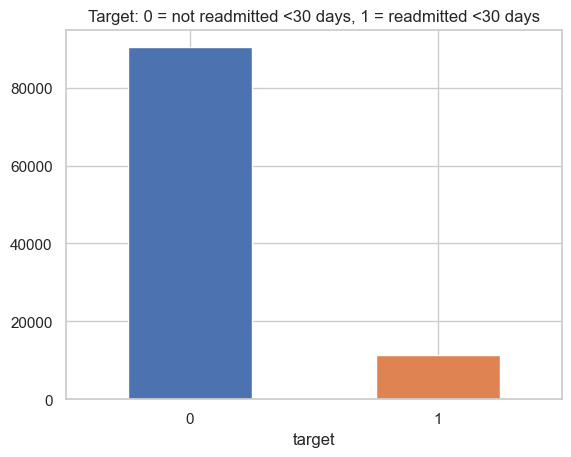

In [40]:
rate = df["target"].mean()
print(f"Readmitted <30 days: {rate:.2%}")
print(f"A model that always says 'No' would get {1 - rate:.2%} accuracy but catch 0 readmissions.")

df["target"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Target: 0 = not readmitted <30 days, 1 = readmitted <30 days")
plt.xticks(rotation=0)
plt.show()

**Finding:** only about **11%** of patients are readmitted within 30 days (imbalanced data).
- Accuracy is misleading.
- Our plan: use **class weights**, use **stratified splits**, **tune the threshold**, and judge with recall / F1 / ROC-AUC / PR-AUC.

## 3.5 Missing values – what we do

| Column | Missing | Decision | Why |
|---|---|---|---|
| `weight` | ~97% | **Drop** | Almost never recorded |
| `medical_specialty` | ~49% | Fill with **"Unknown"** | Missing itself can be informative |
| `payer_code` | ~40% | Fill with **"Unknown"** | Same reason |
| `race` | ~2% | Fill with **"Unknown"** | Very small share |
| `diag_1/2/3` | <1.5% | **"Unknown"** after grouping | Often means "no further diagnosis" |
| `max_glu_serum`, `A1Cresult` | – | Keep **"None"** | It means *test not performed* (a real category) |
| `gender = Unknown/Invalid` | 3 rows | **Drop rows** | Invalid |

In [41]:
df = df.drop(columns=["weight"])

for col in ["race", "payer_code", "medical_specialty"]:
    df[col] = df[col].fillna("Unknown")

df = df[df["gender"] != "Unknown/Invalid"]
df.shape

(101763, 50)

## 3.6 Data leakage – use only information known **at discharge**

| Item | Action |
|---|---|
| `encounter_id`, `patient_nbr` (IDs) | Not used as features (only for splitting and reporting) |
| Patients who **died or went to hospice** | **Remove** – they cannot be readmitted |
| Same patient in train and test | **Split by patient** |
| Scaler / encoder fitted on all data | **Fit on train only** |
| Choosing threshold on the test set | Choose it on the **validation** set |

In [42]:
# Discharge codes for: expired (11), hospice (13, 14), expired at home/facility (19, 20, 21)
died_or_hospice = [11, 13, 14, 19, 20, 21]

print("Rows before:", len(df))
df = df[~df["discharge_disposition_id"].isin(died_or_hospice)].reset_index(drop=True)
print("Rows after :", len(df))
print(f"Readmission rate now: {df['target'].mean():.2%}")

Rows before: 101763
Rows after : 99340
Readmission rate now: 11.39%


## 3.7 Feature engineering
We turn raw codes into simple, meaningful features. These steps use fixed rules (nothing is learned from the data), so there is no leakage.

**Group the ID codes** (based on `IDS_mapping.csv`)

In [43]:
def group_admission_type(i):
    return {1: "Emergency", 2: "Urgent", 3: "Elective"}.get(i, "Other/Unknown")

def group_admission_source(i):
    if i in (1, 2, 3): return "Referral"
    if i in (4, 5, 6, 10, 18, 19, 22, 25, 26): return "Transfer"
    if i == 7: return "Emergency room"
    return "Other/Unknown"

In [44]:
def group_discharge(i):
    if i == 1: return "Home"
    if i in (6, 8): return "Home with health service"
    if i in (3, 4, 5, 22, 23, 24): return "Post-acute facility"
    if i in (2, 9, 10, 12, 15, 16, 17, 27, 28, 29, 30): return "Transfer to other hospital"
    if i == 7: return "Left against advice"
    return "Other/Unknown"

df["admission_type"] = df["admission_type_id"].map(group_admission_type)
df["admission_source"] = df["admission_source_id"].map(group_admission_source)
df["discharge_group"] = df["discharge_disposition_id"].map(group_discharge)

**Group the diagnosis codes** (hundreds of ICD-9 codes → a few families)

In [45]:

def group_diagnosis(code):
    if pd.isna(code): 
        return "Unknown"

    code = str(code)

    if code == "?":
        return "Unknown"

    if code.startswith(("E", "V")): 
        return "Other"

    v = float(code)

    if 250 <= v < 251: return "Diabetes"
    if 390 <= v <= 459 or v == 785: return "Circulatory"
    if 460 <= v <= 519 or v == 786: return "Respiratory"
    if 520 <= v <= 579 or v == 787: return "Digestive"
    if 580 <= v <= 629 or v == 788: return "Genitourinary"
    if 710 <= v <= 739: return "Musculoskeletal"
    if 800 <= v <= 999: return "Injury"
    if 140 <= v <= 239: return "Neoplasms"

    return "Other"


for col in ["diag_1", "diag_2", "diag_3"]:
    df[col + "_grp"] = df[col].map(group_diagnosis)

df["diag_1_grp"].value_counts()


diag_1_grp
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Unknown               20
Name: count, dtype: int64

**Age, prior visits and medication features**

In [46]:
# age band like '[40-50)' -> middle value 45
df["age_mid"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

In [47]:
med_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
            "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
            "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
            "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]

df["n_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["n_meds_changed"] = df[med_cols].isin(["Up", "Down"]).sum(axis=1)

In [48]:
# Medicines that are 'No' for >= 99.5% of patients carry almost no information -> drop them
near_constant = [c for c in med_cols if (df[c] == "No").mean() >= 0.995]
med_keep = [c for c in med_cols if c not in near_constant]
print("Dropped medicine columns:", near_constant)

Dropped medicine columns: ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [49]:
# Counts are very skewed -> log1p makes them smoother
for col in ["number_outpatient", "number_emergency", "number_inpatient", "total_prior_visits"]:
    df[col + "_log"] = np.log1p(df[col])

**Final list of features**

In [50]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_diagnoses", "age_mid", "n_meds_active", "n_meds_changed",
            "number_outpatient_log", "number_emergency_log", "number_inpatient_log", "total_prior_visits_log"]

cat_cols = ["race", "gender", "admission_type", "admission_source", "discharge_group", "payer_code",
            "medical_specialty", "diag_1_grp", "diag_2_grp", "diag_3_grp", "max_glu_serum",
            "A1Cresult", "change", "diabetesMed"] + med_keep

feature_cols = num_cols + cat_cols
print(len(num_cols), "numeric +", len(cat_cols), "categorical =", len(feature_cols), "features")
print("Missing values in features:", df[feature_cols].isnull().sum().sum())

12 numeric + 24 categorical = 36 features
Missing values in features: 176694


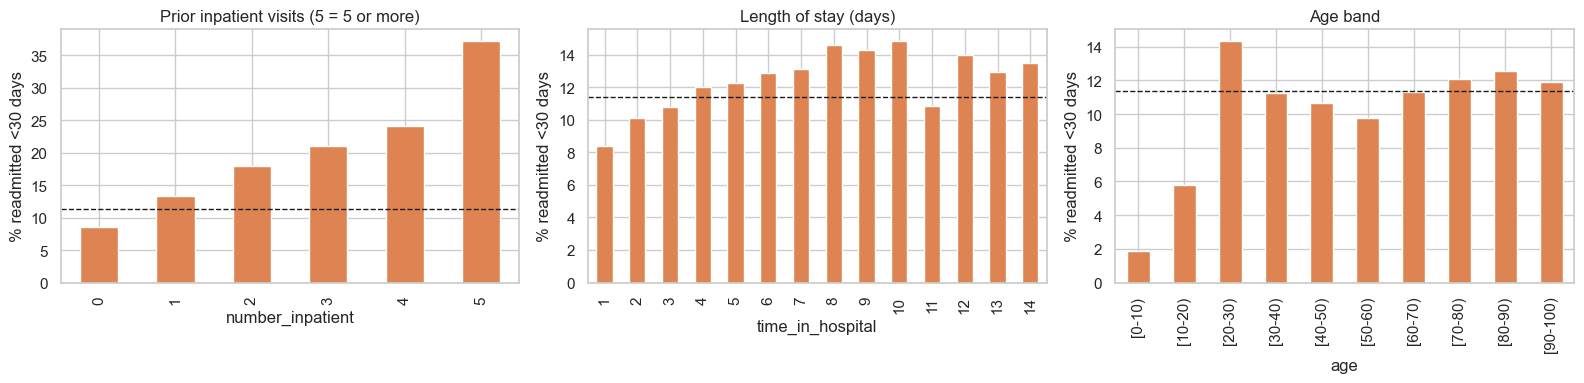

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df.groupby(df["number_inpatient"].clip(upper=5))["target"].mean().mul(100).plot(kind="bar", ax=axes[0], color="#DD8452")
axes[0].set_title("Prior inpatient visits (5 = 5 or more)")

df.groupby(df["time_in_hospital"])["target"].mean().mul(100).plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Length of stay (days)")

df.groupby("age")["target"].mean().mul(100).plot(kind="bar", ax=axes[2], color="#DD8452")
axes[2].set_title("Age band")

for ax in axes:
    ax.axhline(df["target"].mean() * 100, color="k", ls="--", lw=1)
    ax.set_ylabel("% readmitted <30 days")
plt.tight_layout()
plt.show()

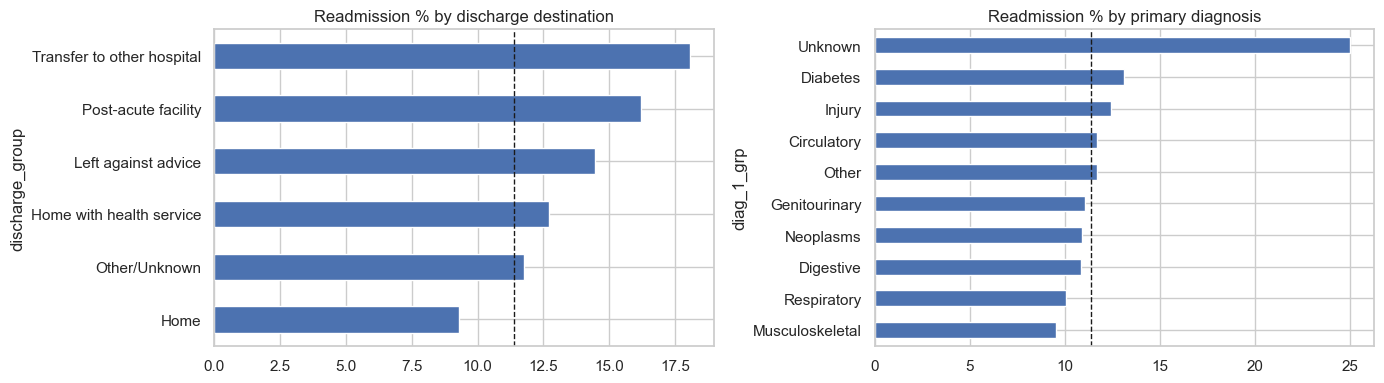

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df.groupby("discharge_group")["target"].mean().mul(100).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Readmission % by discharge destination")

df.groupby("diag_1_grp")["target"].mean().mul(100).sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Readmission % by primary diagnosis")

for ax in axes:
    ax.axvline(df["target"].mean() * 100, color="k", ls="--", lw=1)
plt.tight_layout()
plt.show()

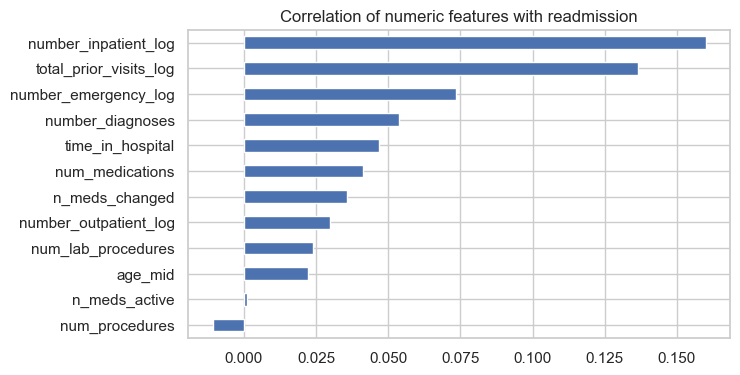

In [53]:
corr = df[num_cols + ["target"]].corr()
corr["target"].drop("target").sort_values().plot(kind="barh", figsize=(7, 4), color="#4C72B0")
plt.title("Correlation of numeric features with readmission")
plt.show()

**Findings**
- Risk **rises with the number of prior inpatient visits** and a little with length of stay.
- Risk also differs by **discharge destination** and **diagnosis**.
- All correlations are **weak** (the strongest is about 0.17). This is a hard, noisy problem, so we expect only a **moderate ROC-AUC (about 0.6–0.7)**.

##  Train / validation / test split (by patient)
About **70% train · 15% validation · 15% test**.
`StratifiedGroupKFold` keeps the same readmission rate in every set **and** makes sure a patient is only in **one** set.

In [54]:
X = df[feature_cols]
y = df["target"]
groups = df["patient_nbr"]

# Step 1: take out the test set (about 1/7 of data)
split1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(split1.split(X, y, groups))

In [55]:
# Step 2: from the rest, take out the validation set (about 1/6)
split2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr, va = next(split2.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]

In [56]:
summary = pd.DataFrame({
    "rows":     [len(X_train), len(X_val), len(X_test)],
    "patients": [groups.iloc[i].nunique() for i in (train_idx, val_idx, test_idx)],
    "readmitted_%": [round(s.mean() * 100, 2) for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
summary

,rows,patients,readmitted_%
train,71235,49974,11.46
validation,14055,9990,11.47
test,14050,10023,10.98


In [57]:
# Check: no patient should be in two sets (all three numbers must be 0)
p_train, p_val, p_test = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
print("Shared patients:", len(p_train & p_val), len(p_train & p_test), len(p_val & p_test))

Shared patients: 0 0 0


## Encoding and scaling 

In [58]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cat_cols),
])

Xtr = preprocess.fit_transform(X_train).astype("float32")   # fit ONLY on train
Xva = preprocess.transform(X_val).astype("float32")
Xte = preprocess.transform(X_test).astype("float32")

ytr, yva, yte = y_train.values, y_val.values, y_test.values
print("Train:", Xtr.shape, "| Validation:", Xva.shape, "| Test:", Xte.shape)

Train: (71235, 141) | Validation: (14055, 141) | Test: (14050, 141)


# Part  MLP Architecture (Keras Sequential)

| Part | Choice | Reason |
|---|---|---|
| Hidden layers | `Dense(128, relu)` → `Dense(64, relu)` | ReLU is simple and trains well |
| Regularisation | `Dropout(0.3)` + L2 | Prevents memorising the training data |
| Output | `Dense(1, sigmoid)` | Gives a probability between 0 and 1 |
| Loss | `binary_crossentropy` | Standard for 2-class problems |
| Optimizer | `Adam` (lr = 0.001) | Reliable default |
| Imbalance | `class_weight` | Missing a readmission costs more |
| Early stopping | watch `val_auc` | Stops before overfitting |

In [59]:
def build_mlp(input_dim, hidden=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 else None

    model = keras.Sequential(name="readmission_mlp")
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy",
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),
                           keras.metrics.AUC(name="auc"),
                           keras.metrics.AUC(name="pr_auc", curve="PR")])
    return model

In [60]:
demo_model = build_mlp(Xtr.shape[1])
demo_model.summary()

Model: "readmission_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,497 (103.50 KB)

 Trainable params: 26,497 (103.50 KB)

 Non-trainable params: 0 (0.00 B)

#  Training & Evaluation
## 5.1 Class weights

In [61]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

Class weights: {0: np.float64(0.5646848989298454), 1: np.float64(4.364889705882353)}


## 5.2 Experiments
We train 5 versions (max 30 epochs, early stopping on validation AUC) and compare them **on the validation set only**:

| Run | What changes |
|---|---|
| A | Base model (batch 256, class weights) |
| B | Smaller batch size (64) |
| C | **No** class weights |
| D | **No** dropout / L2 |
| E | Deeper network (3 layers) |

In [62]:
experiments = {
    "A base (bs=256, class wt)":  dict(batch=256, cw=True,  hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "B batch size 64":            dict(batch=64,  cw=True,  hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "C no class weights":         dict(batch=256, cw=False, hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "D no dropout / L2":          dict(batch=256, cw=True,  hidden=(128, 64),      dropout=0.0, l2=0.0),
    "E deeper (256-128-64)":      dict(batch=256, cw=True,  hidden=(256, 128, 64), dropout=0.3, l2=1e-4),
}
histories, models, rows = {}, {}, []

In [63]:
for name, cfg in experiments.items():
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(Xtr.shape[1], hidden=cfg["hidden"], dropout=cfg["dropout"], l2=cfg["l2"])
    stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)

    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=30, batch_size=cfg["batch"],
              class_weight=class_weight if cfg["cw"] else None, callbacks=[stop], verbose=0)

    p_train = m.predict(Xtr, batch_size=4096, verbose=0).ravel()
    p_val = m.predict(Xva, batch_size=4096, verbose=0).ravel()
    rows.append({"experiment": name,
                 "best_epoch": int(np.argmax(h.history["val_auc"])) + 1,
                 "train_auc": roc_auc_score(ytr, p_train),
                 "val_auc": roc_auc_score(yva, p_val),
                 "val_recall@0.5": recall_score(yva, p_val >= 0.5),
                 "val_precision@0.5": precision_score(yva, p_val >= 0.5, zero_division=0)})
    histories[name], models[name] = h.history, m
    print("done:", name)

done: A base (bs=256, class wt)
done: B batch size 64
done: C no class weights
done: D no dropout / L2
done: E deeper (256-128-64)


In [64]:
results = pd.DataFrame(rows).set_index("experiment").round(4)
results["auc_gap"] = (results["train_auc"] - results["val_auc"]).round(4)
results

,best_epoch,train_auc,val_auc,val_recall@0.5,val_precision@0.5,auc_gap
experiment,,,,,,
"A base (bs=256, class wt)",8,0.7084,0.6769,0.6700,0.1769,0.0315
B batch size 64,6,0.6977,0.6756,0.6842,0.1711,0.0221
C no class weights,5,0.6889,0.6682,0.0074,0.7059,0.0207
D no dropout / L2,3,0.7007,0.6688,0.6911,0.1657,0.0319
E deeper (256-128-64),9,0.7191,0.6715,0.6408,0.1715,0.0476


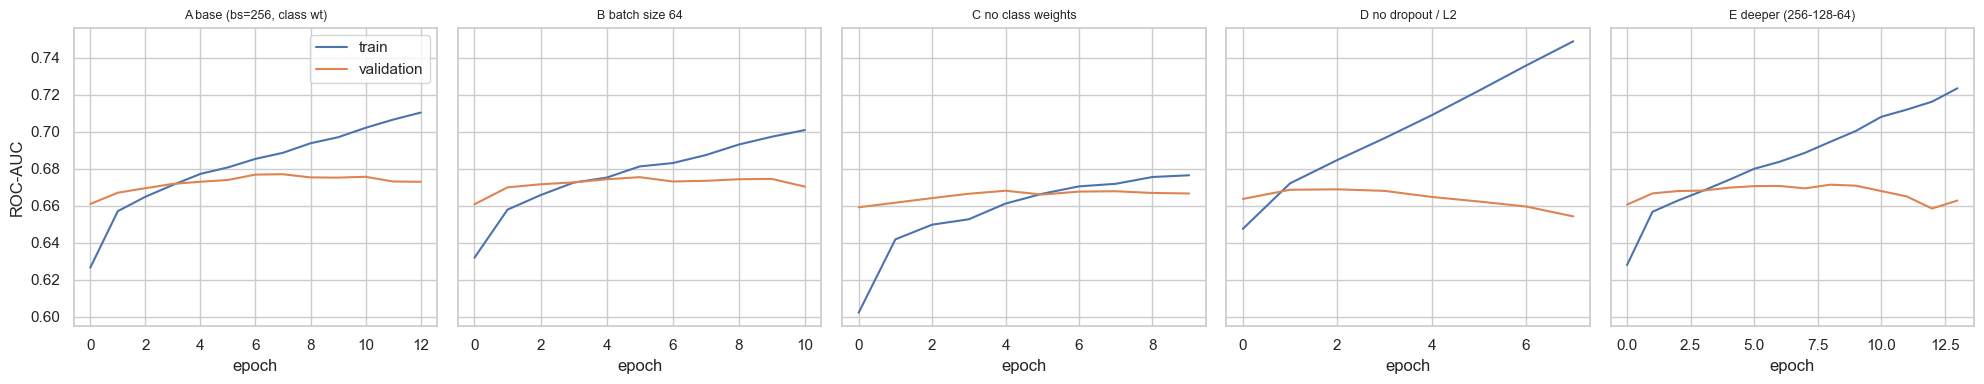

In [65]:
# Learning curves: train vs validation AUC
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["auc"], label="train")
    ax.plot(h["val_auc"], label="validation")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend()
plt.tight_layout()
plt.show()

**How to read this**
- **Batch size and depth** change ROC-AUC only slightly – the differences are small.
- **Class weights** do not improve ranking. They change the *operating point*: without them (run C) recall at 0.5 is near zero, because the model almost never predicts the rare class.
- **Dropout / L2** (run D without them) make the model overfit earlier. Early stopping keeps the train–validation gap small.
- So the architecture is **not critical**. Class weights and the threshold matter much more.

## 5.3 Pick the final model (best validation AUC)

In [66]:
best_name = results["val_auc"].idxmax()
model = models[best_name]
print("Selected:", best_name)

p_tr = model.predict(Xtr, batch_size=4096, verbose=0).ravel()
p_va = model.predict(Xva, batch_size=4096, verbose=0).ravel()

print("Train ROC-AUC     :", round(roc_auc_score(ytr, p_tr), 4))
print("Validation ROC-AUC:", round(roc_auc_score(yva, p_va), 4))

Selected: A base (bs=256, class wt)
Train ROC-AUC     : 0.7084
Validation ROC-AUC: 0.6769


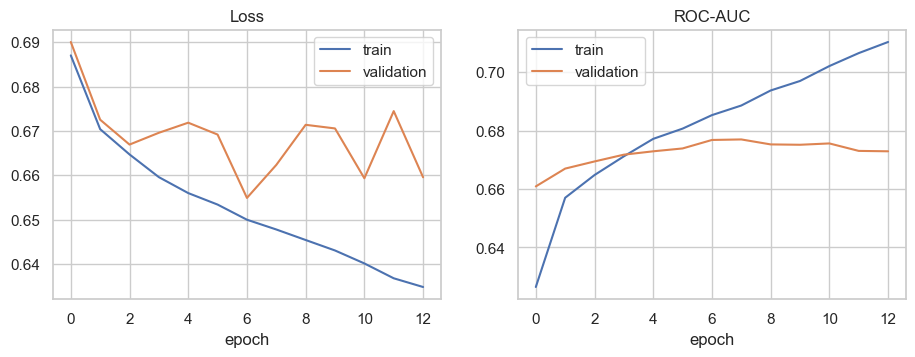

In [67]:
h = histories[best_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation"); axes[0].set_title("Loss")
axes[1].plot(h["auc"], label="train");  axes[1].plot(h["val_auc"], label="validation");  axes[1].set_title("ROC-AUC")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
plt.show()

## 5.4 Choose the decision threshold (on validation data)
The model gives a probability. **0.5 is not sacred.** Because missing a patient costs more than a false alarm, we compare:
- **0.5** – default
- **F1-optimal** – best balance of precision and recall
- **F2-optimal within capacity** – favours recall, but flags at most `CAPACITY` of patients (the hospital cannot call everyone). **This is our final choice.**

In [68]:
CAPACITY = 0.40    # the team can follow up at most 40% of discharged patients (change for your hospital)

def evaluate(y_true, prob, threshold, name):
    pred = (prob >= threshold).astype(int)
    return {"model": name,
            "threshold": round(float(threshold), 3),
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob),
            "flagged_%": 100 * pred.mean()}

In [69]:
def pick_threshold(y_true, prob, capacity=CAPACITY):
    # best F2 score among thresholds that flag <= capacity of patients
    prec, rec, thr = precision_recall_curve(y_true, prob)
    f2 = 5 * prec[:-1] * rec[:-1] / (4 * prec[:-1] + rec[:-1] + 1e-12)
    flagged = 1 - np.searchsorted(np.sort(prob), thr, side="left") / len(prob)
    ok = flagged <= capacity
    return float(thr[ok][np.argmax(f2[ok])])

prec, rec, thr = precision_recall_curve(yva, p_va)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
thr_f1 = float(thr[np.argmax(f1[:-1])])
thr_cap = pick_threshold(yva, p_va)

In [70]:
ops = pd.DataFrame([evaluate(yva, p_va, 0.5, "default 0.5"),
                    evaluate(yva, p_va, thr_f1, "F1-optimal"),
                    evaluate(yva, p_va, thr_cap, "F2 within capacity (final)")]).set_index("model").round(3)
ops

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,flagged_%
model,,,,,,,,
default 0.5,0.500,0.605,0.177,0.670,0.280,0.677,0.221,43.444
F1-optimal,0.546,0.687,0.195,0.552,0.288,0.677,0.221,32.451
F2 within capacity (final),0.517,0.636,0.184,0.632,0.285,0.677,0.221,39.452


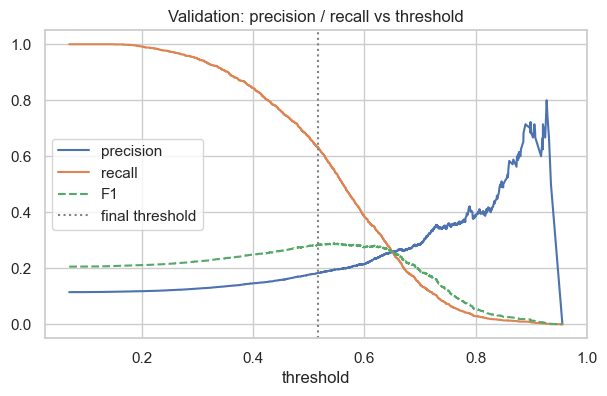

In [71]:
plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.plot(thr, f1[:-1], label="F1", ls="--")
plt.axvline(thr_cap, color="grey", ls=":", label="final threshold")
plt.xlabel("threshold"); plt.title("Validation: precision / recall vs threshold"); plt.legend()
plt.show()

In [72]:
FINAL_THRESHOLD = thr_cap
print(f"Final threshold: {FINAL_THRESHOLD:.3f}")

Final threshold: 0.517


## 5.5 Final evaluation on the **test** set
We compare the MLP with two simple baselines: "always No" and Logistic Regression. The test set is used **only now**.

In [73]:
p_te = model.predict(Xte, batch_size=4096, verbose=0).ravel()

logreg = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, ytr)
p_va_lr = logreg.predict_proba(Xva)[:, 1]
p_te_lr = logreg.predict_proba(Xte)[:, 1]
thr_lr = pick_threshold(yva, p_va_lr)

In [74]:
test_table = pd.DataFrame([
    evaluate(yte, np.zeros(len(yte)), 0.5, "Baseline: always No"),
    evaluate(yte, p_te_lr, thr_lr, "Logistic Regression"),
    evaluate(yte, p_te, 0.5, "MLP @ 0.5"),
    evaluate(yte, p_te, thr_f1, "MLP @ F1-optimal"),
    evaluate(yte, p_te, FINAL_THRESHOLD, "MLP @ final threshold"),
]).set_index("model").round(3)
test_table

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,flagged_%
model,,,,,,,,
Baseline: always No,0.500,0.890,0.000,0.000,0.000,0.500,0.110,0.000
Logistic Regression,0.487,0.624,0.161,0.577,0.252,0.649,0.192,39.295
MLP @ 0.5,0.500,0.598,0.163,0.645,0.260,0.663,0.199,43.388
MLP @ F1-optimal,0.546,0.681,0.175,0.516,0.262,0.663,0.199,32.278
MLP @ final threshold,0.517,0.630,0.169,0.604,0.264,0.663,0.199,39.310


In [75]:
pred_te = (p_te >= FINAL_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred_te).ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

TN=7,916  FP=4,592  FN=611  TP=931


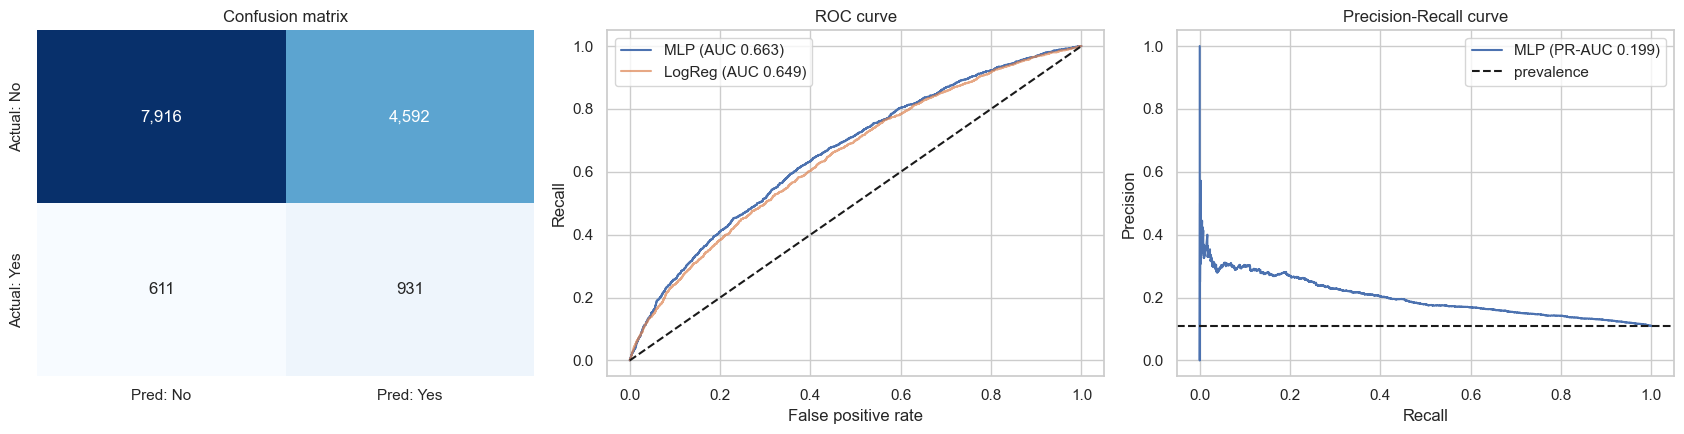

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.heatmap(confusion_matrix(yte, pred_te), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(yte, p_te)
fpr_l, tpr_l, _ = roc_curve(yte, p_te_lr)
axes[1].plot(fpr, tpr, label=f"MLP (AUC {roc_auc_score(yte, p_te):.3f})")
axes[1].plot(fpr_l, tpr_l, label=f"LogReg (AUC {roc_auc_score(yte, p_te_lr):.3f})", alpha=0.7)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC curve"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("Recall"); axes[1].legend()

pr, rc, _ = precision_recall_curve(yte, p_te)
axes[2].plot(rc, pr, label=f"MLP (PR-AUC {average_precision_score(yte, p_te):.3f})")
axes[2].axhline(yte.mean(), color="k", ls="--", label="prevalence")
axes[2].set_title("Precision-Recall curve"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()
plt.tight_layout()
plt.show()

**Interpretation**
- **ROC-AUC / PR-AUC** show how well the model *ranks* patients. Compare PR-AUC with the prevalence (about 0.11), not with 0.5.
- **Accuracy is lower than "always No" on purpose.** Our threshold flags many patients to catch more readmissions, while "always No" catches none.
- The MLP and Logistic Regression perform **similarly**. For tabular data this is common, so we do not claim the MLP is magic.
- Overall performance is **moderate**, matching published work on this dataset. Readmission also depends on things not in the data (home support, medicine adherence, follow-up care).

# Part 6 · Error Analysis
- **False Negatives (FN):** readmitted patients we missed → most costly.
- **False Positives (FP):** patients flagged but not readmitted → wasted follow-up effort.

In [77]:
test_df = X_test.copy()
test_df["actual"] = yte
test_df["prob"] = p_te
test_df["pred"] = pred_te
test_df["outcome"] = np.select(
    [(test_df.actual == 1) & (test_df.pred == 1),
     (test_df.actual == 0) & (test_df.pred == 1),
     (test_df.actual == 1) & (test_df.pred == 0)],
    ["TP", "FP", "FN"], default="TN")

test_df["outcome"].value_counts()

outcome
TN    7916
FP    4592
TP     931
FN     611
Name: count, dtype: int64

In [78]:
print(f"Missed readmissions (FN): {fn:,} of {fn + tp:,} = {fn / (fn + tp):.1%}")
print(f"False alarms (FP): {fp:,} of {fp + tp:,} flagged = {fp / (fp + tp):.1%}")

Missed readmissions (FN): 611 of 1,542 = 39.6%
False alarms (FP): 4,592 of 5,523 flagged = 83.1%


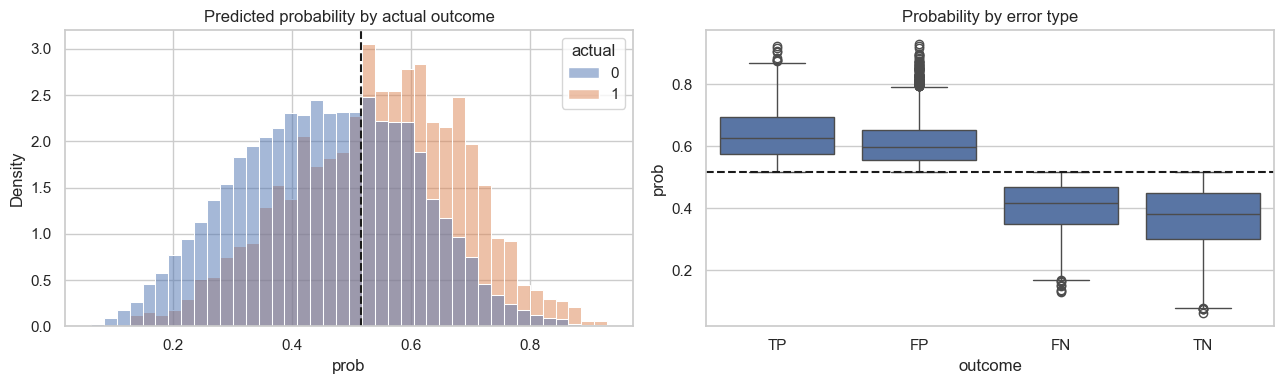

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=test_df, x="prob", hue="actual", bins=40, stat="density", common_norm=False, ax=axes[0])
axes[0].axvline(FINAL_THRESHOLD, color="k", ls="--")
axes[0].set_title("Predicted probability by actual outcome")

sns.boxplot(data=test_df, x="outcome", y="prob", order=["TP", "FP", "FN", "TN"], ax=axes[1])
axes[1].axhline(FINAL_THRESHOLD, color="k", ls="--")
axes[1].set_title("Probability by error type")
plt.tight_layout()
plt.show()

### 6.1 What do the errors look like?

In [80]:
profile_cols = ["time_in_hospital", "number_inpatient_log", "total_prior_visits_log",
                "num_medications", "number_diagnoses", "age_mid"]
test_df.groupby("outcome")[profile_cols].mean().reindex(["TP", "FP", "FN", "TN"]).round(2)

,time_in_hospital,number_inpatient_log,total_prior_visits_log,num_medications,number_diagnoses,age_mid
outcome,,,,,,
TP,5.26,0.78,0.99,18.50,7.98,67.14
FP,5.31,0.61,0.82,18.08,8.06,68.39
FN,4.14,0.12,0.31,15.07,7.33,66.70
TN,3.73,0.10,0.26,14.52,6.98,63.88


In [81]:
prior = df.loc[X_test.index, "number_inpatient"]
prior.groupby(test_df["outcome"]).mean().reindex(["TP", "FP", "FN", "TN"]).round(2)

outcome
TP    1.75
FP    1.20
FN    0.18
TN    0.14
Name: number_inpatient, dtype: float64

### 6.2 Where does the model miss the most? (recall by group)

In [82]:
seg = test_df.copy()
seg["prior_inpatient"] = df.loc[seg.index, "number_inpatient"].clip(upper=3).astype(str).replace({"3": "3+"})
seg["discharge_group"] = df.loc[seg.index, "discharge_group"]
seg["age_band"] = df.loc[seg.index, "age"]
seg["primary_dx"] = seg["diag_1_grp"]

def recall_by(col):
    pos = seg[seg.actual == 1]
    out = pd.DataFrame({"patients": seg.groupby(col).size(),
                        "readmit_rate_%": seg.groupby(col)["actual"].mean() * 100,
                        "recall_%": pos.groupby(col)["pred"].mean() * 100})
    out["missed_%"] = 100 - out["recall_%"]
    return out.round(1)

In [83]:
recall_by("prior_inpatient")

,patients,readmit_rate_%,recall_%,missed_%
prior_inpatient,,,,
0,9523,8.6,36.5,63.5
1,2643,12.4,77.7,22.3
2,1006,16.8,89.9,10.1
3+,878,25.7,99.6,0.4


In [84]:
recall_by("discharge_group")

,patients,readmit_rate_%,recall_%,missed_%
discharge_group,,,,
Home,8467,8.9,43.7,56.3
Home with health service,1920,11.6,58.7,41.3
Left against advice,98,11.2,54.5,45.5
Other/Unknown,657,13.2,56.3,43.7
Post-acute facility,2586,16.2,89.0,11.0
Transfer to other hospital,322,15.8,86.3,13.7


In [85]:
recall_by("primary_dx")

,patients,readmit_rate_%,recall_%,missed_%
primary_dx,,,,
Circulatory,4249,10.8,59.2,40.8
Diabetes,1270,12.8,71.8,28.2
Digestive,1285,11.1,59.2,40.8
Genitourinary,766,10.4,61.3,38.7
Injury,960,13.5,71.5,28.5
Musculoskeletal,709,9.7,58.0,42.0
Neoplasms,432,9.0,59.0,41.0
Other,2492,11.2,54.1,45.9
Respiratory,1887,9.6,56.6,43.4


### 6.3 Fairness check (gender and race)

In [86]:
def group_performance(col):
    rows = []
    for name, d in seg.assign(**{col: df.loc[seg.index, col]}).groupby(col):
        if len(d) >= 200 and d.actual.nunique() == 2:
            rows.append({col: name, "n": len(d),
                         "readmit_rate_%": round(d.actual.mean() * 100, 1),
                         "ROC-AUC": round(roc_auc_score(d.actual, d.prob), 3),
                         "recall_%": round(recall_score(d.actual, d.pred) * 100, 1)})
    return pd.DataFrame(rows).set_index(col)

group_performance("gender")

,n,readmit_rate_%,ROC-AUC,recall_%
gender,,,,
Female,7737,11.1,0.663,60.1
Male,6313,10.9,0.664,60.7


In [87]:
group_performance("race")

,n,readmit_rate_%,ROC-AUC,recall_%
race,,,,
?,316,11.4,0.686,52.8
AfricanAmerican,2606,11.2,0.671,62.3
Caucasian,10520,10.9,0.657,59.8
Hispanic,294,9.9,0.742,69.0
Other,228,10.5,0.722,75.0


### 6.4 Most confident mistakes

In [88]:
cases = test_df.join(df.loc[X_test.index, ["encounter_id", "age", "number_inpatient"]])
show = ["encounter_id", "age", "number_inpatient", "discharge_group", "time_in_hospital", "diag_1_grp", "prob"]

print("Highest-probability FALSE POSITIVES (flagged, but not readmitted):")
cases[cases.outcome == "FP"].nlargest(5, "prob")[show].round(3)

Highest-probability FALSE POSITIVES (flagged, but not readmitted):


,encounter_id,age,number_inpatient,discharge_group,time_in_hospital,diag_1_grp,prob
97107,413795030,[30-40),8,Transfer to other hospital,3,Diabetes,0.930
85081,277605918,[30-40),14,Home,1,Other,0.923
12577,51731412,[60-70),3,Transfer to other hospital,13,Other,0.918
34582,109512750,[60-70),10,Home,3,Digestive,0.898
93250,362628476,[70-80),9,Home with health service,3,Other,0.896


In [89]:
print("Lowest-probability FALSE NEGATIVES (readmitted, but model thought they were safe):")
cases[cases.outcome == "FN"].nsmallest(5, "prob")[show].round(3)

Lowest-probability FALSE NEGATIVES (readmitted, but model thought they were safe):


,encounter_id,age,number_inpatient,discharge_group,time_in_hospital,diag_1_grp,prob
24058,82984626,[60-70),0,Home,2,Respiratory,0.128
71841,217398228,[20-30),0,Home,2,Diabetes,0.132
71101,213630534,[40-50),0,Home,2,Respiratory,0.134
65059,186075150,[50-60),0,Home,1,Other,0.148
73363,224532132,[50-60),0,Other/Unknown,2,Musculoskeletal,0.153


### 6.5 Error-analysis conclusions

| Error type | What we see | Likely cause | What to do |
|---|---|---|---|
| **False negatives** | They look like normal patients: few or **no prior inpatient visits**, short stays. Missed more often for first-time patients. | The data has **no** information on home support, medicine adherence or follow-up care. | Add richer features; give the low-risk group a cheap automatic reminder. |
| **False positives** | They look more like true positives: more prior visits, longer stays, more medicines. | Complex patients are high-risk but not certain to return. Follow-up may even have prevented a return. | Accept some false alarms because the cost is low; use **risk tiers** to ration intensive care. |
| **Class imbalance** | Only about 11% are positive, so precision stays low. | Base-rate maths. | Judge with PR-AUC and lift, not accuracy. |
| **Subgroups** | Large groups perform similarly; very small groups are unstable. | Small samples. | Monitor subgroups and collect more data before real use. |

### Which features does the model use? (permutation importance)

In [90]:
def predict_raw(frame):
    return model.predict(preprocess.transform(frame).astype("float32"), batch_size=4096, verbose=0).ravel()

sample = X_val.sample(min(6000, len(X_val)), random_state=SEED)
y_sample = y_val.loc[sample.index].values
base_auc = roc_auc_score(y_sample, predict_raw(sample))
print("Base AUC on sample:", round(base_auc, 4))

Base AUC on sample: 0.6849


In [91]:
rng = np.random.default_rng(SEED)
importance = {}

for col in feature_cols:
    drops = []
    for _ in range(2):
        shuffled = sample.copy()
        shuffled[col] = rng.permutation(shuffled[col].values)
        drops.append(base_auc - roc_auc_score(y_sample, predict_raw(shuffled)))
    importance[col] = np.mean(drops)

importance = pd.Series(importance).sort_values(ascending=False)

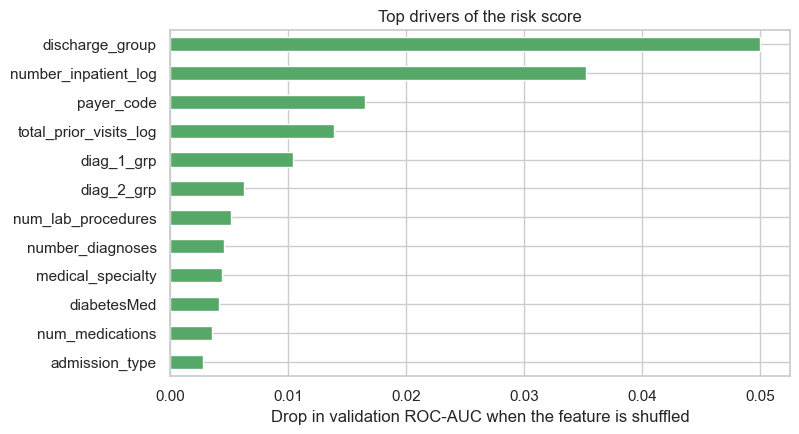

In [92]:
importance.head(12).iloc[::-1].plot(kind="barh", figsize=(8, 4.5), color="#55A868")
plt.xlabel("Drop in validation ROC-AUC when the feature is shuffled")
plt.title("Top drivers of the risk score")
plt.show()

# Part 7 · Business Insights & Recommendations
## 7.1 Patient-level prediction report
One row per test patient, made by our model. We also add a **risk tier** (cut-offs come from validation data only):
- **High** = top 10% of risk scores
- **Medium** = above the alert threshold, but not High
- **Low** = below the alert threshold

In [93]:
report = pd.DataFrame({
    "Patient ID": "P" + df.loc[X_test.index, "patient_nbr"].astype(str).values,
    "Encounter ID": df.loc[X_test.index, "encounter_id"].values,
    "Actual readmission": np.where(yte == 1, "Yes", "No"),
    "Predicted result": np.where(pred_te == 1, "Yes", "No"),
    "Risk probability": p_te.round(3),
})

cut_high = np.quantile(p_va, 0.90)
report["Risk tier"] = np.select([p_te >= cut_high, p_te >= FINAL_THRESHOLD], ["High", "Medium"], default="Low")
report.head(10)

,Patient ID,Encounter ID,Actual readmission,Predicted result,Risk probability,Risk tier
0,P82637451,35754,No,Yes,0.564,Medium
1,P21239181,150048,No,No,0.208,Low
2,P98427861,325866,No,No,0.377,Low
3,P101002446,358776,No,No,0.499,Low
4,P104672268,377268,No,No,0.448,Low
5,P66274866,449142,No,No,0.336,Low
6,P106936875,464994,No,No,0.353,Low
7,P86240259,486156,Yes,Yes,0.691,High
8,P56714769,669954,No,Yes,0.574,Medium
9,P3376278,715086,No,Yes,0.696,High


In [94]:
outcome = test_df["outcome"].values
examples = pd.concat([report[outcome == o].sample(3, random_state=SEED).assign(Outcome=o)
                      for o in ["TP", "FN", "FP", "TN"]])
examples.reset_index(drop=True)

,Patient ID,Encounter ID,Actual readmission,Predicted result,Risk probability,Risk tier,Outcome
0,P43808607,299095640,Yes,Yes,0.570,Medium,TP
1,P112167837,40206252,Yes,Yes,0.528,Medium,TP
2,P44186427,191832558,Yes,Yes,0.675,High,TP
3,P72272151,54516954,Yes,No,0.374,Low,FN
4,P1748466,106611048,Yes,No,0.231,Low,FN
5,P11585304,42563706,Yes,No,0.502,Low,FN
6,P111341538,209290380,No,Yes,0.632,Medium,FP
7,P60008211,179149626,No,Yes,0.591,Medium,FP
8,P24813144,116657034,No,Yes,0.575,Medium,FP
9,P98388396,206979876,No,No,0.457,Low,TN


In [95]:
print("Top 10 highest-risk patients:")
report.sort_values("Risk probability", ascending=False).head(10).reset_index(drop=True)

Top 10 highest-risk patients:


,Patient ID,Encounter ID,Actual readmission,Predicted result,Risk probability,Risk tier
0,P90489195,413795030,No,Yes,0.930,High
1,P90489195,263115954,Yes,Yes,0.924,High
2,P90489195,277605918,No,Yes,0.923,High
3,P4251672,51731412,No,Yes,0.918,High
4,P90489195,265100100,Yes,Yes,0.915,High
5,P56990070,156381930,Yes,Yes,0.906,High
6,P90489195,259613184,Yes,Yes,0.904,High
7,P19921905,109512750,No,Yes,0.898,High
8,P89308323,362628476,No,Yes,0.896,High
9,P90489195,271182900,No,Yes,0.895,High


In [96]:
report.to_csv("readmission_predictions_test.csv", index=False)
print("Saved", len(report), "rows to readmission_predictions_test.csv")

Saved 14050 rows to readmission_predictions_test.csv


## 7.2 How can the hospital prioritise follow-up?

In [97]:
report["actual"] = yte
tier = report.groupby("Risk tier").agg(patients=("actual", "size"), readmitted=("actual", "sum"))
tier = tier.reindex(["High", "Medium", "Low"])

tier["share_of_patients_%"] = 100 * tier["patients"] / tier["patients"].sum()
tier["readmission_rate_%"] = 100 * tier["readmitted"] / tier["patients"]
tier["share_of_all_readmissions_%"] = 100 * tier["readmitted"] / tier["readmitted"].sum()
tier["lift_vs_average"] = tier["readmission_rate_%"] / (100 * yte.mean())
tier.round(2)

,patients,readmitted,share_of_patients_%,readmission_rate_%,share_of_all_readmissions_%,lift_vs_average
Risk tier,,,,,,
High,1328,346,9.45,26.05,22.44,2.37
Medium,4195,585,29.86,13.95,37.94,1.27
Low,8527,611,60.69,7.17,39.62,0.65


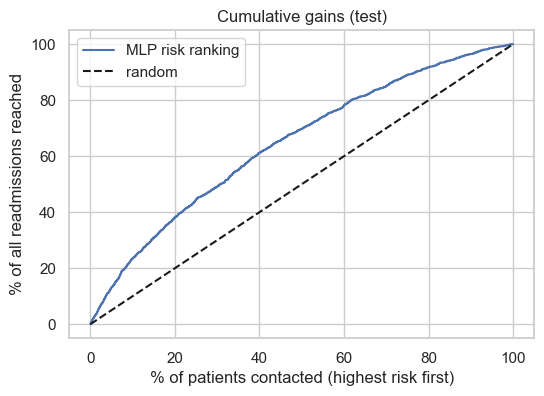

In [98]:
# Cumulative gains: if we can only contact the top X% of patients, how many readmissions do we reach?
order = np.argsort(-p_te)
captured = np.cumsum(yte[order]) / yte.sum()
share = np.arange(1, len(yte) + 1) / len(yte)

plt.figure(figsize=(6, 4))
plt.plot(share * 100, captured * 100, label="MLP risk ranking")
plt.plot([0, 100], [0, 100], "k--", label="random")
plt.xlabel("% of patients contacted (highest risk first)")
plt.ylabel("% of all readmissions reached")
plt.title("Cumulative gains (test)"); plt.legend()
plt.show()

In [99]:
for q in (0.1, 0.2, 0.3):
    k = int(q * len(yte))
    print(f"Top {int(q * 100)}% of patients -> {captured[k - 1]:.1%} of readmissions (random would give {q:.0%})")

Top 10% of patients -> 23.4% of readmissions (random would give 10%)
Top 20% of patients -> 38.1% of readmissions (random would give 20%)
Top 30% of patients -> 49.1% of readmissions (random would give 30%)


### Simple economics (illustrative numbers – replace with real hospital figures)
Intervene on a group if its readmission rate is above the **break-even rate**:

$$\text{break-even} = \frac{\text{cost of one intervention}}{\text{effectiveness} \times \text{cost of one readmission}}$$

In [100]:
COST_READMISSION = 15000    # cost of one avoidable readmission
COST_INTERVENTION = 500     # cost of one follow-up package
EFFECTIVENESS = 0.20        # share of readmissions the intervention prevents

break_even = COST_INTERVENTION / (EFFECTIVENESS * COST_READMISSION)
tier["worth_intervening"] = np.where(tier["readmission_rate_%"] / 100 >= break_even, "Yes", "No")

print(f"Break-even readmission rate: {break_even:.1%}")
tier[["patients", "readmission_rate_%", "worth_intervening"]].round(2)

Break-even readmission rate: 16.7%


,patients,readmission_rate_%,worth_intervening
Risk tier,,,
High,1328,26.05,Yes
Medium,4195,13.95,No
Low,8527,7.17,No


## 7.3 Short business findings (numbers update automatically)

Test set: 14,050 encounters, 11.0% readmitted within 30 days
1. MLP ROC-AUC = 0.656 (PR-AUC 0.196 vs 0.110 random). Logistic Regression = 0.649.
2. At threshold 0.52 the model catches 60% of readmissions (precision 17%), flagging 39% of patients.
3. High-risk tier (9% of patients): readmission rate 24.1% = 2.2x average, holds 20% of all readmissions. Low tier: 7.3%.
4. Top drivers: discharge_group, number_inpatient_log, total_prior_visits_log
5. Train-validation AUC gap = 0.018 (no heavy overfitting).
6. Without class weights (run C), validation recall at 0.5 = 1%.

### Recommendations

1. **Tiered follow-up programme**
   - **High tier:** nurse call within 48 hours, follow-up appointment booked before discharge, medicine review, home-health referral if needed.
   - **Medium tier:** cheaper contact (scheduled call, clear written instructions). Under the placeholder costs in 7.2, the full care package may not break even for this tier.
   - **Low tier:** automatic reminder or patient-portal message. This is cheap and covers missed (false-negative) patients.
2. **Prioritise by prior visits and discharge destination.** The importance chart shows these are strong drivers, so patients with repeated recent admissions or discharged to facilities / home health are the first targets.
3. **Review the diabetes medicine plan at discharge.** Medication variables appear among the drivers. This shows *association*, not cause.
4. **Match the threshold to capacity and cost.** Re-tune using the hospital's real cost of a readmission and of an intervention.
5. **Improve the data, not only the model.** Add home support, adherence, lab trends, clinical notes and community follow-up data. Missed cases look "ordinary" in the current data.
6. **Governance before real use.** Retrain on recent data, validate with clinicians, audit subgroups (race, gender, age, insurance), monitor drift and keep a human in the loop. Race and payer are used here for the exercise and need a fairness review before real use.

### Limitations
- Data is from **1999–2008 US hospitals**; practice, coding and patients have changed.
- A patient can have several encounters (the split is by patient, but they are still correlated inside the training set).
- Performance is **moderate**: the model helps *prioritise* patients, it does not diagnose.
- Cost numbers in 7.2 are **placeholders**.
- This is an **educational prototype**, not a clinically validated system.